# Network Intrusion Detection: CICIDS2017 Data Visualization

## Part 1 — Dataset Pitch & Metadata Profile

### Dataset Source

- Dataset: CICIDS2017 Network Attack Detection
- File: CICIDS2017.csv
- Source: https://www.kaggle.com/datasets/datcolabssnet/cicids2017-network-attack-detection-dataset
- Original research: https://www.unb.ca/cic/datasets/ids-2017.html
- Records: 61,381
- Columns: 79
- Traffic classifications: 15

### Dataset Description

The CICIDS2017 dataset contains network traffic observations
collected through controlled cybersecurity experiments by the
Canadian Institute for Cybersecurity at the University of
New Brunswick.

The dataset includes benign network traffic and various attack
types, including DDoS, brute-force attacks, port scanning,
infiltration, and SQL injection.

### Reason for Selection

I selected this dataset because of my interest in cybersecurity,
network security, and threat detection. Analyzing network traffic
patterns can help identify relationships between communication
behavior and different types of cyberattacks.

### Key Variables

- Flow Duration: Duration of a network flow in microseconds.
- Total Fwd Packets: Number of forward-direction packets.
- Total Backward Packets: Number of backward-direction packets.
- Total Length of Fwd Packets: Forward traffic volume in bytes.
- Total Length of Bwd Packets: Backward traffic volume in bytes.
- Packet Length Mean: Average packet length in bytes.
- Flow Bytes/s: Network traffic transmission rate.
- Flow Packets/s: Packet transmission rate.
- Label: Network traffic or attack classification.

### Research Objective

Use Matplotlib and Seaborn to explore network traffic trends,
attack distributions, statistical correlations, and relationships
between network communication characteristics.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization appearance
sns.set_theme(style="whitegrid")

# Load the downloaded dataset
df = pd.read_csv("CICIDS2017.csv")

# Remove whitespace from column names
df.columns = df.columns.str.strip()

# Display dataset dimensions
print(f"Records: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# Preview the dataset
df.head()

Records: 61,381
Columns: 79


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,9101782,5,0,30,0,6,6,6.000000,0.000000,...,20,997.0,0.0,997,997,9100785.0,0.0,9100785,9100785,DDoS
1,21,8971397,9,15,115,188,27,0,12.777778,10.639288,...,32,0.0,0.0,0,0,0.0,0.0,0,0,FTP-Patator
2,80,11602599,8,5,371,11632,371,0,46.375000,131.168308,...,32,788.0,0.0,788,788,6599964.0,0.0,6599964,6599964,DoS GoldenEye
3,21,250,2,1,14,0,14,0,7.000000,9.899495,...,32,0.0,0.0,0,0,0.0,0.0,0,0,FTP-Patator
4,8193,42,1,1,0,6,0,0,0.000000,0.000000,...,40,0.0,0.0,0,0,0.0,0.0,0,0,PortScan


### Initial Dataset Inspection

The dataset was successfully imported and contains 61,381
network flow records across 79 columns, including 78
numerical features and one categorical target variable.

The initial inspection confirms that the dataset contains
packet measurements, traffic volumes, communication timing,
and cybersecurity attack classifications.

Preliminary data profiling identified 26 missing values,
64 infinite values, and 6,806 duplicate records. These
findings will guide the data preparation process before
visualization.

### Data Cleaning and Feature Engineering

Before generating visualizations, the dataset will be
prepared by handling invalid numerical values, converting
measurement units, and deriving additional traffic metrics.

These steps will improve the accuracy and readability of
the subsequent visualizations while preserving the original
dataset.

In [2]:
# Create a working copy to preserve the original dataset
df_clean = df.copy()

# Replace positive and negative infinite values with NaN
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Calculate total packets per network flow
df_clean["Total Packets"] = (
    df_clean["Total Fwd Packets"] +
    df_clean["Total Backward Packets"]
)

# Calculate total transmitted bytes per network flow
df_clean["Total Bytes"] = (
    df_clean["Total Length of Fwd Packets"] +
    df_clean["Total Length of Bwd Packets"]
)

# Convert flow duration from microseconds to seconds
df_clean["Flow Duration (s)"] = (
    df_clean["Flow Duration"] / 1_000_000
)

# Display data quality summary
print("Data Quality Summary")
print("-" * 40)

print(f"Records: {df_clean.shape[0]:,}")
print(f"Columns: {df_clean.shape[1]}")
print(f"Missing values: {df_clean.isna().sum().sum()}")
print(f"Infinite values: {np.isinf(df_clean.select_dtypes(include='number')).sum().sum()}")
print(f"Duplicate records retained: {df.duplicated().sum():,}")

# Display descriptive statistics for the derived variables
print("\nDescriptive Statistics")

df_clean[
    ["Flow Duration (s)", "Total Packets", "Total Bytes"]
].describe().round(2)

Data Quality Summary
----------------------------------------
Records: 61,381
Columns: 82
Missing values: 90
Infinite values: 0
Duplicate records retained: 6,806

Descriptive Statistics


,Flow Duration (s),Total Packets,Total Bytes
count,61381.00,61381.00,61381.00
mean,23.64,12.98,5885.26
std,37.20,146.07,162067.09
min,0.00,2.00,0.00
25%,0.00,2.00,6.00
50%,4.87,5.00,31.00
75%,18.56,13.00,4753.00
max,120.00,19512.00,23438662.00


### Data Preparation Results

The prepared dataset contains 61,381 records and 82 columns,
including three newly derived numerical variables. All 64
infinite values were converted to missing values, resulting
in 90 missing values and zero infinite values.

The 6,806 identical records were retained because separate
network flows may share identical recorded characteristics.

The descriptive statistics reveal the following:

- The average network flow duration is 23.64 seconds,
  with a maximum of 120 seconds.
- The average packet count is 12.98 packets per flow,
  with a maximum of 19,512 packets.
- The average traffic volume is 5,885.26 bytes per flow,
  with a maximum of 23,438,662 bytes.

The substantial differences between the median, mean, and
maximum values suggest right-skewed distributions and the
presence of unusually large network flows.

The prepared dataset is suitable for the subsequent
visualizations.

## Part 2 — Line Chart: Network Flow Duration and Packet Volume

### Objective

Investigate how the average number of transmitted packets
changes as network flow duration increases.

Since the dataset does not contain timestamps, an ordered
numerical progression of flow duration will be used instead
of a chronological time series.

Network flows will be grouped into 10-second duration
intervals, and the average packet count will be calculated
for each interval. A Matplotlib line chart will visualize
the resulting pattern and help identify sudden increases,
decreases, and potential traffic anomalies.

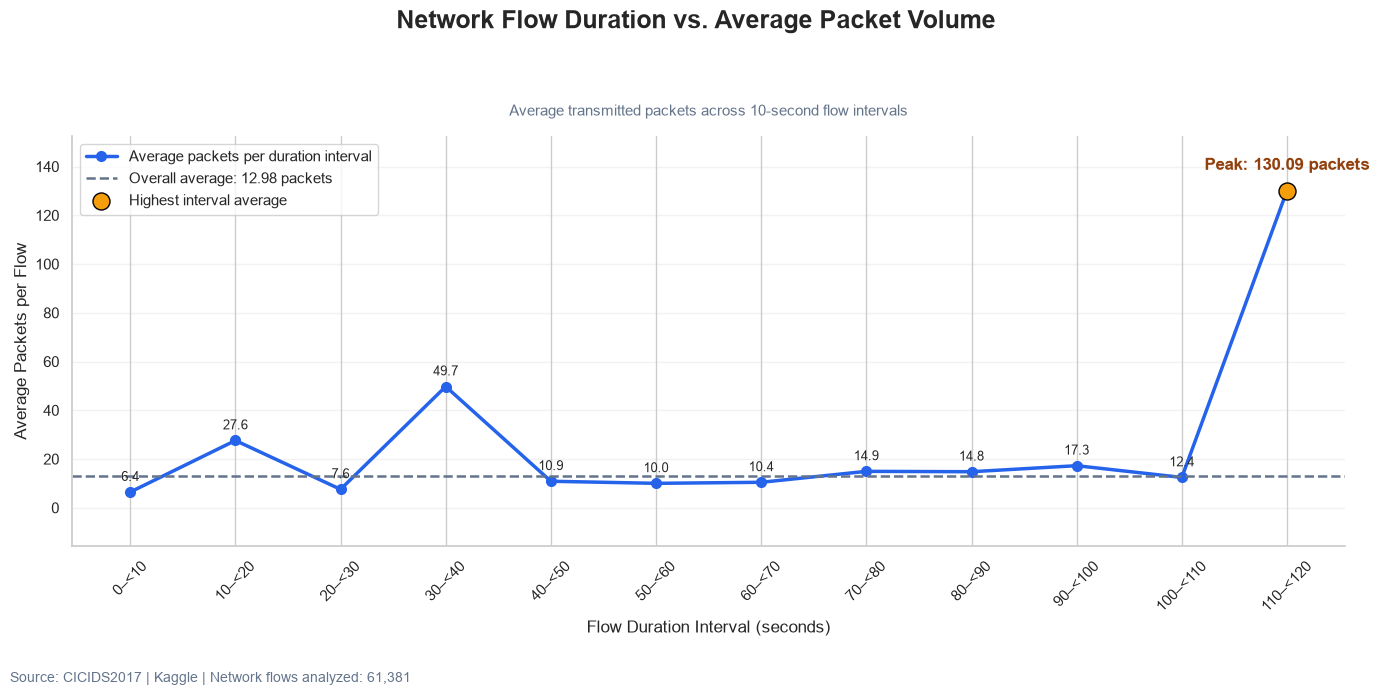

,Average Packet Count,Network Flow Count
Duration Interval,,
"[0, 10)",6.44,38519
"[10, 20)",27.60,7666
"[20, 30)",7.56,643
"[30, 40)",49.74,493
"[40, 50)",10.87,196
"[50, 60)",10.02,258
"[60, 70)",10.45,3132
"[70, 80)",14.94,542
"[80, 90)",14.78,2069


In [4]:
# Define visualization colors
BLUE = "#2563EB"
AMBER = "#F59E0B"
GRAY = "#64748B"

# Define 10-second duration intervals
bins = np.arange(0, 131, 10)

# Group network flows into duration intervals
df_clean["Duration Interval"] = pd.cut(
    df_clean["Flow Duration (s)"],
    bins=bins,
    include_lowest=True,
    right=False
)

# Calculate average packet count and sample size
duration_trend = (
    df_clean.groupby("Duration Interval", observed=True)
    ["Total Packets"]
    .agg(["mean", "count"])
)

# Calculate overall average for the plotted observations
overall_mean = (
    df_clean.loc[
        df_clean["Duration Interval"].notna(),
        "Total Packets"
    ].mean()
)

# Identify the highest average packet count
peak_interval = duration_trend["mean"].idxmax()
peak_value = duration_trend["mean"].max()

# Prepare chart coordinates
x = np.array([
    interval.mid for interval in duration_trend.index
])

peak_x = peak_interval.mid

# Create visualization
fig, ax = plt.subplots(figsize=(14, 7))

# Main trend
ax.plot(
    x,
    duration_trend["mean"],
    color=BLUE,
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Average packets per duration interval"
)

# Overall reference average
ax.axhline(
    overall_mean,
    color=GRAY,
    linestyle="--",
    linewidth=1.8,
    label=f"Overall average: {overall_mean:.2f} packets"
)

# Highlight the highest observed average
ax.scatter(
    peak_x,
    peak_value,
    color=AMBER,
    s=150,
    edgecolor="black",
    zorder=5,
    label="Highest interval average"
)

# Annotate the peak
ax.annotate(
    f"Peak: {peak_value:.2f} packets",
    xy=(peak_x, peak_value),
    xytext=(0, 15),
    textcoords="offset points",
    ha="center",
    fontweight="bold",
    color="#92400E"
)

# Annotate average values
for position, value in zip(x, duration_trend["mean"]):
    if position != peak_x:
        ax.annotate(
            f"{value:.1f}",
            (position, value),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

# Main title
fig.suptitle(
    "Network Flow Duration vs. Average Packet Volume",
    fontsize=18,
    fontweight="bold"
)

# Analytical subtitle
ax.set_title(
    "Average transmitted packets across 10-second flow intervals",
    fontsize=11,
    color=GRAY,
    pad=15
)

# Axis labels
ax.set_xlabel("Flow Duration Interval (seconds)", fontsize=12)
ax.set_ylabel("Average Packets per Flow", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels([
    f"{int(i.left)}–<{int(i.right)}"
    for i in duration_trend.index
], rotation=45)

# Improve chart readability
ax.legend(loc="best", frameon=True)
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.18)

sns.despine()

# Source attribution and sample size
fig.text(
    0.01, 0.02,
    f"Source: CICIDS2017 | Kaggle | "
    f"Network flows analyzed: {duration_trend['count'].sum():,}",
    fontsize=10,
    color=GRAY
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()

# Display supporting statistical results
duration_trend.rename(columns={
    "mean": "Average Packet Count",
    "count": "Network Flow Count"
}).round(2)

### Results and Stakeholder Interpretation

The line chart reveals a non-linear relationship between network
flow duration and average packet count. The highest average occurs
in the 110–120 second interval at 130.09 packets per flow, while
the 0–10 second interval contains the most observations (38,519)
and the lowest average of 6.44 packets per flow.

### Key Stakeholder Findings

- **Primary anomaly:** The 110–120 second interval exhibits the
  highest average packet volume, warranting further investigation.
- **Secondary spike:** The 30–40 second interval averages
  49.74 packets per flow.
- **Dominant traffic pattern:** Short-duration flows account
  for the majority of network observations.
- **Security implication:** Longer-duration flows with elevated
  packet volumes may warrant additional monitoring.

### Analytical Limitations

Unequal sample sizes and extreme packet counts may influence
the observed averages. Elevated packet volumes alone do not
confirm malicious activity. Further analysis of traffic
classifications is necessary to determine whether these
patterns are associated with specific attack types.

## Part 3 — Bar Chart: Network Traffic Classification Distribution

### Objective

Compare the frequency of the 15 network traffic classifications
within the CICIDS2017 dataset and identify the most and least
represented attack categories.

### Stakeholder Relevance

Understanding traffic distribution helps cybersecurity analysts
evaluate dataset coverage, identify underrepresented attack
categories, and assess potential class imbalance in intrusion
detection systems.

The visualization uses the following color classifications:

- Green: Benign network traffic.
- Red: Attack categories representing at least 1% of records.
- Amber: Underrepresented attack categories below 1%.

The 1% threshold indicates dataset representation, not attack
severity.

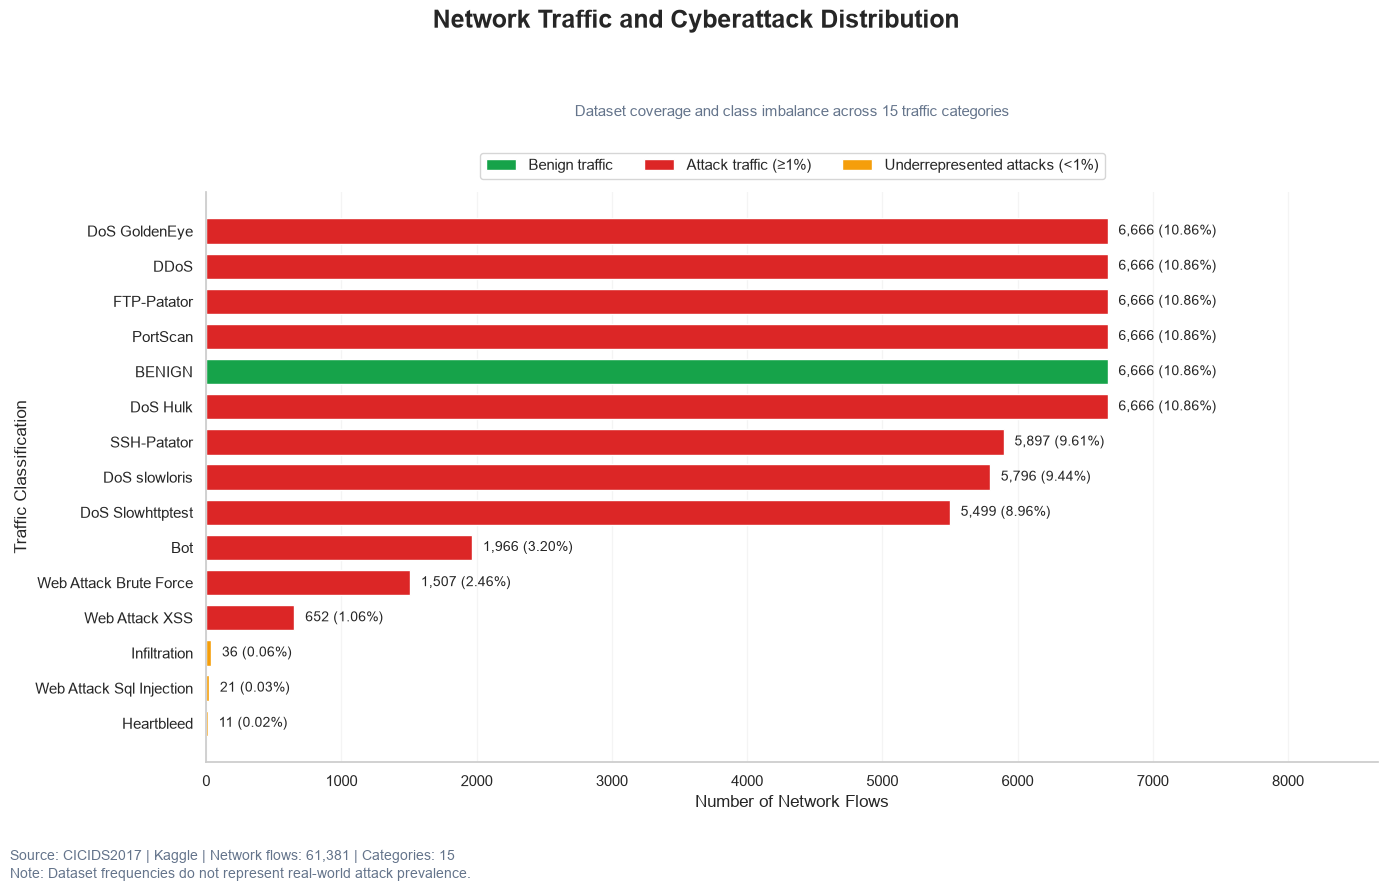

,Network Flow Count,Percentage (%)
Label,,
FTP-Patator,6666,10.86
DoS GoldenEye,6666,10.86
DDoS,6666,10.86
PortScan,6666,10.86
BENIGN,6666,10.86
DoS Hulk,6666,10.86
SSH-Patator,5897,9.61
DoS slowloris,5796,9.44
DoS Slowhttptest,5499,8.96


In [5]:
from matplotlib.patches import Patch

# Define semantic colors
GREEN = "#16A34A"
RED = "#DC2626"
AMBER = "#F59E0B"
GRAY = "#64748B"

# Calculate traffic category counts and percentages
traffic_counts = df_clean["Label"].value_counts().sort_values()
total_flows = traffic_counts.sum()
traffic_pct = traffic_counts / total_flows * 100

# Apply semantic color coding
colors = [
    GREEN if label == "BENIGN"
    else AMBER if traffic_pct[label] < 1
    else RED
    for label in traffic_counts.index
]

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(14, 9))

bars = ax.barh(
    traffic_counts.index,
    traffic_counts.values,
    color=colors,
    height=0.72
)

# Annotate each bar with record count and percentage
for bar, count, pct in zip(
    bars, traffic_counts.values, traffic_pct.values
):
    ax.text(
        bar.get_width() + 80,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.2f}%)",
        va="center",
        fontsize=10
    )

# Configure title and subtitle
fig.suptitle(
    "Network Traffic and Cyberattack Distribution",
    fontsize=18,
    fontweight="bold"
)

ax.set_title(
    "Dataset coverage and class imbalance across 15 traffic categories",
    fontsize=11,
    color=GRAY,
    pad=55
)

# Configure axis labels
ax.set_xlabel("Number of Network Flows", fontsize=12)
ax.set_ylabel("Traffic Classification", fontsize=12)

# Create semantic legend
legend_elements = [
    Patch(facecolor=GREEN, label="Benign traffic"),
    Patch(facecolor=RED, label="Attack traffic (≥1%)"),
    Patch(facecolor=AMBER, label="Underrepresented attacks (<1%)")
]

ax.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=True
)

# Configure chart appearance
ax.set_xlim(0, traffic_counts.max() * 1.30)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

sns.despine()

# Add source attribution and analytical context
fig.text(
    0.01, 0.035,
    f"Source: CICIDS2017 | Kaggle | "
    f"Network flows: {total_flows:,} | "
    f"Categories: {len(traffic_counts)}",
    fontsize=10,
    color=GRAY
)

fig.text(
    0.01, 0.015,
    "Note: Dataset frequencies do not represent real-world attack prevalence.",
    fontsize=10,
    color=GRAY
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

# Display supporting statistics
traffic_summary = pd.DataFrame({
    "Network Flow Count": traffic_counts,
    "Percentage (%)": traffic_pct
})

traffic_summary.sort_values(
    "Network Flow Count",
    ascending=False
).round(2)

### Results and Stakeholder Interpretation

Six traffic categories share the highest representation,
with 6,666 records each: DDoS, FTP-Patator, DoS GoldenEye,
PortScan, DoS Hulk, and BENIGN.

Heartbleed, SQL Injection, and Infiltration are the least
represented attack categories, containing only 11, 21,
and 36 records, respectively. This class imbalance may
limit the effectiveness of intrusion detection models
when identifying underrepresented attacks.

**Stakeholder Recommendation:** Prioritize additional
data collection and targeted model evaluation for
underrepresented attack categories.

**Analytical Limitation:** These frequencies represent
the composition of the research dataset, not actual
real-world cybersecurity threat prevalence.

## Part 4 — Heatmap: Network Traffic Correlations

### Objective

Investigate statistical relationships between network flow
duration, packet counts, transmitted data volumes, and
average packet length using a Pearson correlation matrix.

### Stakeholder Relevance

Understanding relationships between network characteristics
helps security analysts identify potentially redundant
features and determine which traffic measurements may
provide useful information for intrusion detection.

### Color Interpretation

- Dark blue: Strong positive correlation.
- White: Weak or negligible linear correlation.
- Dark red: Strong negative correlation.

Correlation coefficients range from -1 to +1.
Correlation does not establish causation.

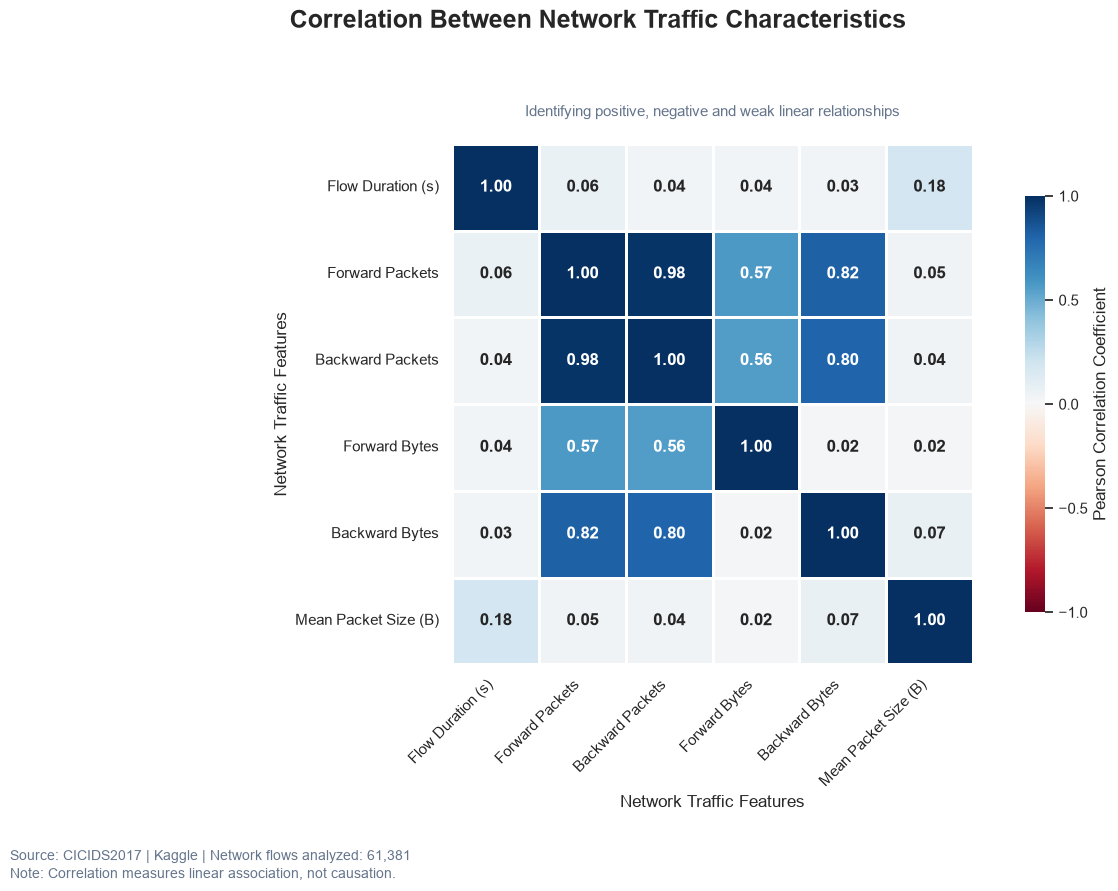

,Flow Duration (s),Forward Packets,Backward Packets,Forward Bytes,Backward Bytes,Mean Packet Size (B)
Flow Duration (s),1.000,0.063,0.039,0.039,0.034,0.185
Forward Packets,0.063,1.000,0.980,0.574,0.816,0.046
Backward Packets,0.039,0.980,1.000,0.561,0.803,0.045
Forward Bytes,0.039,0.574,0.561,1.000,0.017,0.020
Backward Bytes,0.034,0.816,0.803,0.017,1.000,0.071
Mean Packet Size (B),0.185,0.046,0.045,0.020,0.071,1.000


In [6]:
# Select relevant numerical network features
heatmap_data = df_clean[
    [
        "Flow Duration (s)",
        "Total Fwd Packets",
        "Total Backward Packets",
        "Total Length of Fwd Packets",
        "Total Length of Bwd Packets",
        "Packet Length Mean"
    ]
].dropna().copy()

# Rename columns for stakeholder readability
heatmap_data.columns = [
    "Flow Duration (s)",
    "Forward Packets",
    "Backward Packets",
    "Forward Bytes",
    "Backward Bytes",
    "Mean Packet Size (B)"
]

# Calculate Pearson correlation matrix
correlation_matrix = heatmap_data.corr(method="pearson")

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    linecolor="white",
    square=True,
    annot_kws={"size": 12, "weight": "bold"},
    cbar_kws={
        "label": "Pearson Correlation Coefficient",
        "ticks": [-1, -0.5, 0, 0.5, 1],
        "shrink": 0.8
    },
    ax=ax
)

# Configure title and subtitle
fig.suptitle(
    "Correlation Between Network Traffic Characteristics",
    fontsize=18,
    fontweight="bold"
)

ax.set_title(
    "Identifying positive, negative and weak linear relationships",
    fontsize=11,
    color="#64748B",
    pad=20
)

# Label axes
ax.set_xlabel("Network Traffic Features", fontsize=12)
ax.set_ylabel("Network Traffic Features", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# Add source and sample size
fig.text(
    0.01, 0.035,
    f"Source: CICIDS2017 | Kaggle | "
    f"Network flows analyzed: {len(heatmap_data):,}",
    fontsize=10,
    color="#64748B"
)

fig.text(
    0.01, 0.015,
    "Note: Correlation measures linear association, not causation.",
    fontsize=10,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

# Display supporting correlation matrix
correlation_matrix.round(3)

### Results and Stakeholder Interpretation

The correlation matrix reveals a very strong positive
relationship between forward and backward packet counts
(0.98). Forward and backward packet counts also have
strong positive correlations with backward traffic volume
(0.82 and 0.80, respectively).

Network flow duration exhibits weak or negligible linear
relationships with all selected variables, while forward
and backward byte volumes have a negligible correlation
of 0.02.

### Key Stakeholder Findings

| Network Features | Correlation | Relationship |
|---|---:|---|
| Forward and Backward Packets | 0.98 | Very Strong |
| Forward Packets and Backward Bytes | 0.82 | Strong |
| Backward Packets and Backward Bytes | 0.80 | Strong |
| Forward Packets and Forward Bytes | 0.57 | Moderate |
| Backward Packets and Forward Bytes | 0.56 | Moderate |
| Forward and Backward Bytes | 0.02 | Negligible |

### Security Implications

- Highly correlated packet measurements may provide
  redundant information for intrusion detection models.
- Flow duration alone is a poor linear predictor of
  packet counts and traffic volumes.
- Combining multiple traffic characteristics may provide
  a more informative representation of network behavior.

### Stakeholder Recommendation

Evaluate highly correlated features for potential redundancy
when developing intrusion detection models. Retain and
investigate complementary features that may capture
different aspects of network behavior.

### Analytical Limitations

Correlation does not establish causation or prove that
a network flow is malicious. Pearson correlation measures
linear relationships and may be influenced by extreme
observations or differences between attack categories.

## Part 5 — Scatter Plot: Network Flow Duration vs. Traffic Volume

### Objective

Investigate the relationship between network flow duration
and total transmitted data volume to identify clusters,
unusual observations, and potential traffic patterns.

### Stakeholder Relevance

Network security analysts can use bivariate analysis to
investigate whether benign and attack traffic exhibit
different communication characteristics.

### Visualization Strategy

- Green: Benign network traffic.
- Red: Attack traffic.
- Amber: Largest observed traffic volume.
- Transparency: Reduces visual clutter from overlapping records.
- Logarithmic scaling: Improves visibility across a wide
  range of traffic volumes.

Pearson correlation will be calculated to support the
interpretation of the relationship between the two variables.

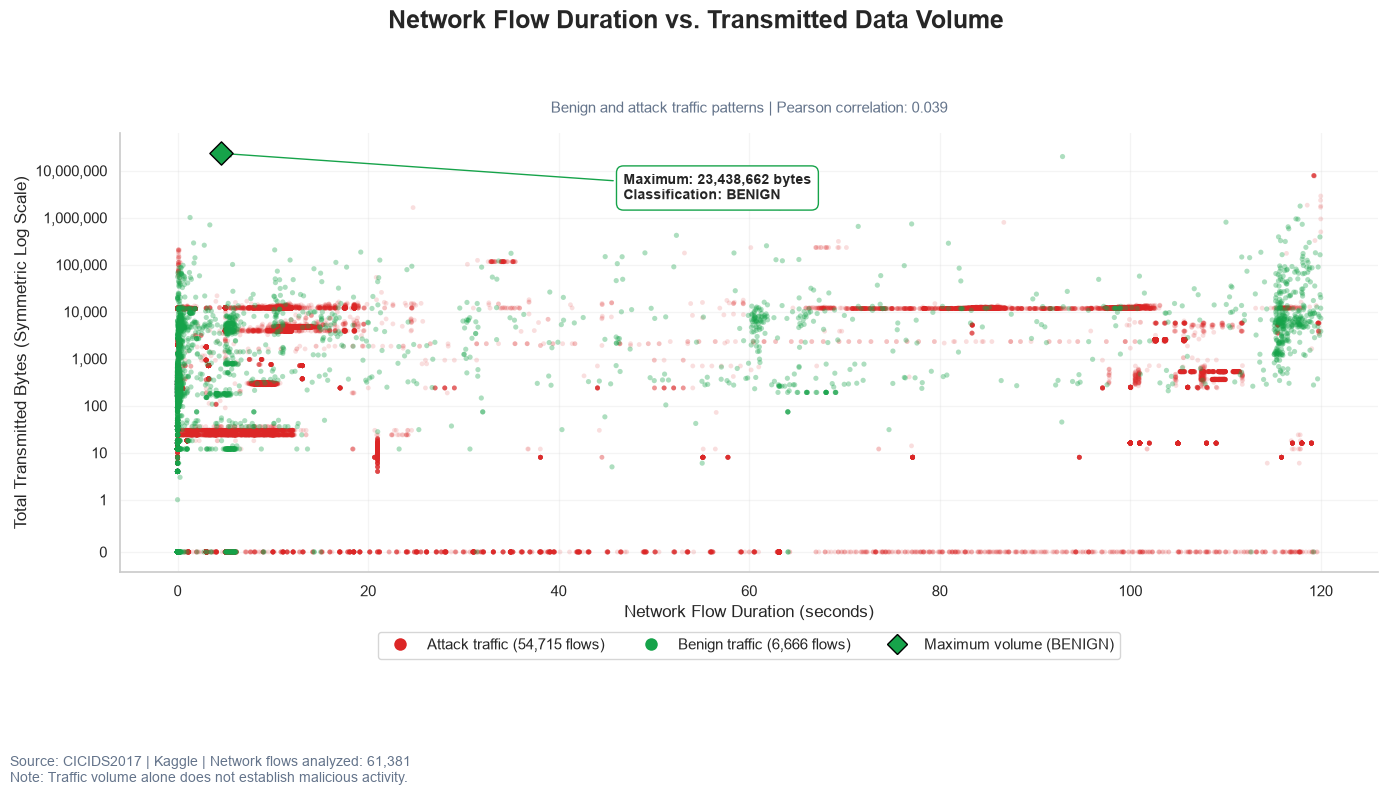

Pearson correlation: 0.0387
Total flows analyzed: 61,381

Largest Observed Network Flow:
Flow Duration (s)    4.592907
Total Bytes          23438662
Label                  BENIGN
Traffic Type           Benign


,Flow_Count,Mean_Duration,Median_Duration,Mean_Bytes,Median_Bytes,Max_Bytes
Traffic Type,,,,,,
Attack,54715,25.13,5.72,5180.44,24.0,7892339
Benign,6666,11.37,0.03,11670.46,221.0,23438662


In [8]:
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

# Define semantic colors
GREEN = "#16A34A"
RED = "#DC2626"
GRAY = "#64748B"

# Select relevant variables and remove missing values
scatter_data = df_clean[
    ["Flow Duration (s)", "Total Bytes", "Label"]
].dropna().copy()

# Exclude invalid negative measurements
scatter_data = scatter_data[
    (scatter_data["Flow Duration (s)"] >= 0) &
    (scatter_data["Total Bytes"] >= 0)
].copy()

# Classify benign and attack traffic
scatter_data["Traffic Type"] = np.where(
    scatter_data["Label"] == "BENIGN",
    "Benign",
    "Attack"
)

# Separate traffic classifications
benign = scatter_data[
    scatter_data["Traffic Type"] == "Benign"
]

attack = scatter_data[
    scatter_data["Traffic Type"] == "Attack"
]

# Calculate Pearson correlation using original measurements
correlation = scatter_data["Flow Duration (s)"].corr(
    scatter_data["Total Bytes"]
)

# Identify the largest observed traffic volume
largest_flow = scatter_data.loc[
    scatter_data["Total Bytes"].idxmax()
]

# Preserve the classification color of the maximum observation
max_color = GREEN if largest_flow["Label"] == "BENIGN" else RED

# Create scatter plot
fig, ax = plt.subplots(figsize=(14, 8))

# Plot attack traffic
ax.scatter(
    attack["Flow Duration (s)"],
    attack["Total Bytes"],
    color=RED,
    alpha=0.15,
    s=12,
    edgecolors="none"
)

# Plot benign traffic
ax.scatter(
    benign["Flow Duration (s)"],
    benign["Total Bytes"],
    color=GREEN,
    alpha=0.35,
    s=14,
    edgecolors="none"
)

# Highlight the maximum using its classification color
ax.scatter(
    largest_flow["Flow Duration (s)"],
    largest_flow["Total Bytes"],
    color=max_color,
    edgecolor="black",
    marker="D",
    s=140,
    zorder=5
)

# Annotate the highlighted observation
ax.annotate(
    f"Maximum: {largest_flow['Total Bytes']:,.0f} bytes\n"
    f"Classification: {largest_flow['Label']}",
    xy=(
        largest_flow["Flow Duration (s)"],
        largest_flow["Total Bytes"]
    ),
    xytext=(0.40, 0.85),
    textcoords="axes fraction",
    fontsize=10,
    fontweight="bold",
    arrowprops={
        "arrowstyle": "->",
        "color": max_color
    },
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": max_color
    }
)

# Use symmetric logarithmic scaling to retain zero values
ax.set_yscale("symlog", linthresh=1)

# Display readable numerical values
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

# Configure title and subtitle
fig.suptitle(
    "Network Flow Duration vs. Transmitted Data Volume",
    fontsize=18,
    fontweight="bold"
)

ax.set_title(
    f"Benign and attack traffic patterns | "
    f"Pearson correlation: {correlation:.3f}",
    fontsize=11,
    color=GRAY,
    pad=15
)

# Configure axis labels
ax.set_xlabel(
    "Network Flow Duration (seconds)",
    fontsize=12
)

ax.set_ylabel(
    "Total Transmitted Bytes (Symmetric Log Scale)",
    fontsize=12
)

# Create a fully opaque stakeholder legend
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor=RED,
        markeredgecolor="none",
        markersize=9,
        label=f"Attack traffic ({len(attack):,} flows)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor=GREEN,
        markeredgecolor="none",
        markersize=9,
        label=f"Benign traffic ({len(benign):,} flows)"
    ),
    Line2D(
        [0], [0],
        marker="D",
        linestyle="none",
        markerfacecolor=max_color,
        markeredgecolor="black",
        markersize=10,
        label=f"Maximum volume ({largest_flow['Label']})"
    )
]

# Position legend below the chart
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True
)

# Configure chart appearance
ax.grid(True, alpha=0.2)
ax.set_axisbelow(True)

sns.despine()

# Add source attribution and analytical context
fig.text(
    0.01, 0.035,
    f"Source: CICIDS2017 | Kaggle | "
    f"Network flows analyzed: {len(scatter_data):,}",
    fontsize=10,
    color=GRAY
)

fig.text(
    0.01, 0.015,
    "Note: Traffic volume alone does not establish malicious activity.",
    fontsize=10,
    color=GRAY
)

plt.tight_layout(rect=[0, 0.12, 1, 0.94])
plt.show()

# Display supporting statistics
print(f"Pearson correlation: {correlation:.4f}")
print(f"Total flows analyzed: {len(scatter_data):,}")

print("\nLargest Observed Network Flow:")
print(largest_flow.to_string())

# Compare benign and attack traffic characteristics
scatter_summary = scatter_data.groupby("Traffic Type").agg(
    Flow_Count=("Label", "count"),
    Mean_Duration=("Flow Duration (s)", "mean"),
    Median_Duration=("Flow Duration (s)", "median"),
    Mean_Bytes=("Total Bytes", "mean"),
    Median_Bytes=("Total Bytes", "median"),
    Max_Bytes=("Total Bytes", "max")
)

scatter_summary.round(2)

### Results and Stakeholder Interpretation

The scatter plot reveals a negligible positive linear relationship
between network flow duration and transmitted data volume, with
a Pearson correlation coefficient of 0.039.

Although several distinct traffic clusters are visible, benign
and attack traffic overlap considerably. These patterns may
result from differences in network protocols, application
behavior, packet sizes, and attack methodologies.

The largest observed traffic volume of 23,438,662 bytes was
classified as benign, demonstrating that high traffic volume
alone is not a reliable indicator of malicious activity.

### Key Stakeholder Findings

| Metric | Result |
|---|---:|
| Total Network Flows | 61,381 |
| Attack Traffic Records | 54,715 |
| Benign Traffic Records | 6,666 |
| Pearson Correlation | 0.039 |
| Maximum Traffic Volume | 23,438,662 bytes |
| Maximum Volume Classification | BENIGN |

### Security Implications

- Flow duration alone is insufficient for predicting
  transmitted traffic volume.
- Benign and attack traffic share overlapping characteristics.
- Large traffic volumes do not necessarily indicate cyberattacks.
- Multiple network features should be evaluated together
  when developing intrusion detection systems.

### Stakeholder Recommendation

Avoid relying exclusively on traffic volume or connection
duration when implementing cybersecurity detection rules.
Combine packet characteristics, communication patterns,
protocol behavior, and other relevant security indicators
to improve threat identification and reduce false positives.

### Analytical Limitations

The dataset contains unequal numbers of benign and attack
observations. Overlapping data points and extreme values
may also influence interpretation. Pearson correlation
measures linear association and does not exclude potential
non-linear relationships.